# Qué preguntas puede sostener la base

La pregunta no se fija en tasas, LEFI ni mora. Este notebook evalúa tres vías: primeras relaciones y alternativas previas; competencia entre acreedores con deudores compartidos; y geografía y mecanismos bancarios. Parte de las advertencias y resultados de 01, 03 y 05, pero se ejecuta sin sus salidas.

CENDEU registra saldos, no solicitudes, rechazos ni originaciones. “Primer acceso” se limita a **primer saldo observado dentro de esta ventana**. No se convierte ausencia observada en exclusión financiera. Se conservan entidades individuales; la etiqueta fintech existente no determina la muestra ni las comparaciones. El indicador de bancos usa el corte regulatorio de balances de mayo de 2025, por lo que no describe cambios históricos de licencia.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Data/processed/ipc.dta').exists())
sys.path.insert(0,str(root/'Code/analysis/liquidez_fintech'))
from common import CENDEU, DATA, HERE, OUT, BASELINE, connect, price_index, figure_style, save_figure, record_inputs
figure_style();con=connect();ipc=price_index()
labels=pd.read_csv(root/'Data/crosswalks/cendeu_lenders.csv')[['ent','name']]
balance=pd.read_stata(DATA/'balances_bancos.dta',convert_categoricals=False)
bank_ids=balance.loc[balance.ym.eq(BASELINE)&balance.es_banco.eq(1),['ent']].copy();bank_ids.ent=bank_ids.ent.astype(int)
assert bank_ids.ent.is_unique and labels.ent.is_unique
con.register('bank_ids',bank_ids)
focal_ids=[72634,70408,45030,384,143,45072,55024,55054,55085,55294]
con.register('focal_ids',pd.DataFrame({'ent':focal_ids}))
calendar={};firm_calendar={}
for directory,target in [('person_lender_5pct',calendar),('firm',firm_calendar)]:
    for path in sorted((CENDEU/directory).glob('*.parquet')):
        rows=con.execute('SELECT DISTINCT year,month FROM read_parquet(?)',[str(path)]).fetchall()
        assert len(rows)==1
        year,month=rows[0];target[pd.Timestamp(year,month,1)]=path
assert len(calendar)==24 and len(firm_calendar)==24
sources=list(calendar.values())+list(firm_calendar.values())+[DATA/'balances_bancos.dta',DATA/'ipc.dta',DATA/'prestamos_depositos_prov.dta',DATA/'inclusion_prov.dta',DATA/'pda_lender_depto.dta',CENDEU/'padron.parquet',root/'Data/crosswalks/cendeu_lenders.csv',root/'Data/crosswalks/provincias_arca_indec.csv']
record_inputs(sources,'06')
def named(d):return d.merge(labels,on='ent',how='left',validate='many_to_one')
pd.set_option('display.float_format',lambda x:f'{x:,.2f}')


## Entrada: qué alternativas tenía la persona

Se toman primeras relaciones positivas con diez entidades identificadas por nombre. Cohortes mensuales de marzo a diciembre de 2025: todas tienen seis meses previos completos y seguimiento a seis meses hasta junio de 2026. Se separan personas sin saldo en los seis meses previos, con otros acreedores sin banco y con banco previo. Se distingue además si alguna vez habían tenido saldo desde agosto de 2024.

Las personas pueden entrar a varias entidades; no sumar filas como personas únicas del sistema. La fuente es la muestra determinística de personas. Un primer saldo puede ser una cesión o un cambio de reporte. La etiqueta “sin saldo previo” se refiere al registro observado, no a la historia crediticia completa.

In [2]:
con.execute("CREATE TEMP TABLE first_any AS SELECT cuit,min(make_date(year,month,1)) AS first_date FROM read_parquet(?) WHERE amount_ars>0 GROUP BY cuit",[str(CENDEU/'person_lender_5pct/*.parquet')])
con.execute("CREATE TEMP TABLE first_focal AS SELECT p.ent,p.cuit,min(make_date(year,month,1)) AS first_date FROM read_parquet(?) p JOIN focal_ids f USING(ent) WHERE amount_ars>0 GROUP BY p.ent,p.cuit",[str(CENDEU/'person_lender_5pct/*.parquet')])
cohorts=[]
for date in pd.date_range('2025-03-01','2025-12-01',freq='MS'):
    prior=[str(calendar[x]) for x in pd.date_range(date-pd.DateOffset(months=6),date-pd.DateOffset(months=1),freq='MS')]
    after3=date+pd.DateOffset(months=3);after6=date+pd.DateOffset(months=6)
    con.execute((HERE/'sql/access_cohort.sql').read_text(),[date,prior,str(calendar[date]),str(calendar[after3]),str(calendar[after6])])
    expected=con.execute('SELECT count(*) FROM first_focal WHERE first_date=?',[date]).fetchone()[0]
    assert con.execute('SELECT count(*) FROM entrant_profiles').fetchone()[0]==expected
    d=con.execute("""SELECT ent,prior_profile,count(*) AS persons,
    count(*) FILTER(WHERE first_any_date=?) AS new_to_window,
    sum(prior_lenders) AS prior_lenders_sum,
    count(*) FILTER(WHERE focal3>0) AS positive3,
    count(*) FILTER(WHERE focal6>0) AS positive6,
    count(*) FILTER(WHERE banks6>0) AS with_other_bank6,
    sum(all0) AS all0,sum(all6) AS all6,sum(focal0) AS focal0,sum(focal6) AS focal6
    FROM entrant_profiles GROUP BY ent,prior_profile""",[date]).fetchdf()
    d['cohort_month']=date
    d0=ipc.loc[ipc.fecha.eq(date),'deflactor'].item();d6=ipc.loc[ipc.fecha.eq(after6),'deflactor'].item()
    for col in ['all0','focal0']:d[col+'_real']=d[col]*d0
    for col in ['all6','focal6']:d[col+'_real']=d[col]*d6
    cohorts.append(d)
access=named(pd.concat(cohorts,ignore_index=True));access.to_csv(OUT/'06_entradas_cohortes.csv',index=False)
metrics=['persons','new_to_window','positive3','positive6','with_other_bank6','all0_real','all6_real','focal0_real','focal6_real']
pooled=access.groupby(['ent','name','prior_profile'])[metrics].sum().reset_index()
pooled['share_pct']=100*pooled.persons/pooled.groupby('ent').persons.transform('sum')
pooled['positive6_pct']=100*pooled.positive6/pooled.persons
pooled['with_other_bank6_pct']=100*pooled.with_other_bank6/pooled.persons
pooled.to_csv(OUT/'06_entradas_perfiles.csv',index=False)
assert np.allclose(pooled.groupby('ent').share_pct.sum(),100)
display(pooled.pivot(index='name',columns='prior_profile',values='share_pct').round(1))


prior_profile,Con banco previo,Sin saldo en seis meses previos,Solo otros acreedores previos
name,,,
BRUBANK S.A.U.,53.30,26.60,20.10
CREDICUOTAS CONSUMO S.A.,74.50,4.80,20.70
CREDITECH SA,42.70,22.20,35.10
Crédito Directo S.A.,46.70,16.80,36.60
MERCADOLIBRE S.R.L.,49.80,40.20,10.00
Moni Online S.A.,84.90,0.70,14.40
NARANJA DIGITAL COMPAÑÍA FINANCIERA S.A.U.,50.80,7.80,41.40
REBA COMPAÑIA FINANCIERA S.A.,66.90,16.30,16.70
TARJETA NARANJA S.A.U.,43.30,32.60,24.10


## Composición de las primeras relaciones

Porcentajes ponderados por número de entradas, no promedio de porcentajes mensuales. Los conteos están en los CSV por cohorte. El gráfico se complementa con seguimiento: una aparición transitoria en el registro no equivale a acceso persistente.

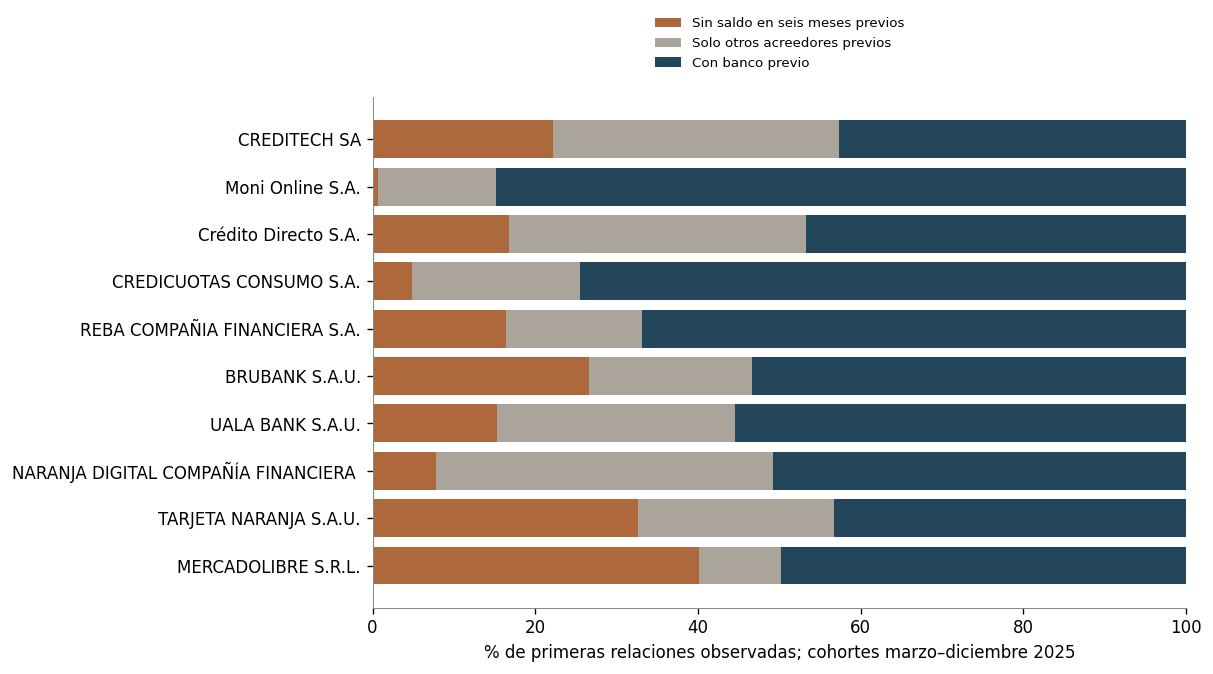

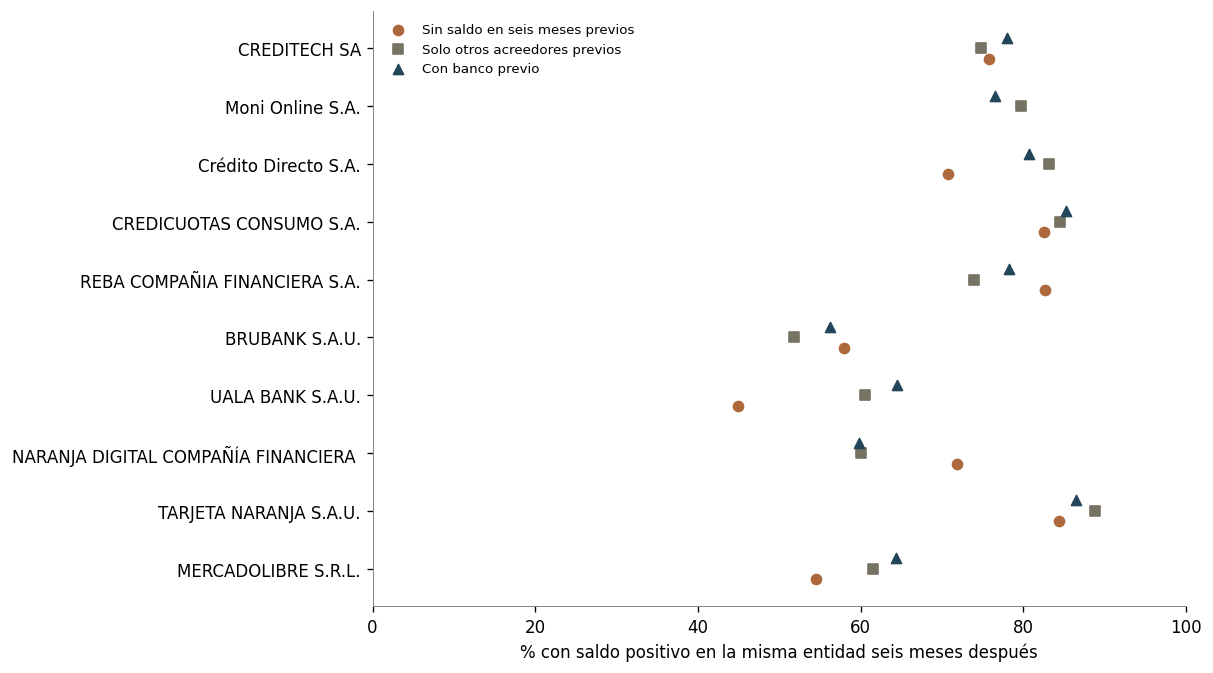

In [3]:
order=['Sin saldo en seis meses previos','Solo otros acreedores previos','Con banco previo']
wide=pooled.pivot(index='ent',columns='prior_profile',values='share_pct').reindex(index=focal_ids,columns=order).fillna(0)
fig,ax=plt.subplots(figsize=(10,5.5),layout='constrained');left=np.zeros(len(wide));y=np.arange(len(wide))
for col,color in zip(order,['#AD683B','#aaa49a','#24465B']):
    ax.barh(y,wide[col],left=left,label=col,color=color);left+=wide[col].to_numpy()
ax.set_yticks(y,[labels.set_index('ent').loc[e,'name'][:36] for e in focal_ids]);ax.set_xlim(0,100)
ax.set_xlabel('% de primeras relaciones observadas; cohortes marzo–diciembre 2025')
ax.legend(loc='upper center',bbox_to_anchor=(.5,1.18),ncol=1,fontsize=8)
save_figure(fig,'06_perfiles_entrada');plt.show()
fig,ax=plt.subplots(figsize=(10,5.5),layout='constrained')
for j,(profile,color) in enumerate(zip(order,['#AD683B','#777363','#24465B'])):
    d=pooled.loc[pooled.prior_profile.eq(profile)].set_index('ent').reindex(focal_ids)
    ax.scatter(d.positive6_pct.where(d.persons.ge(100)),y+(j-1)*.18,label=profile,color=color,marker=['o','s','^'][j])
ax.set_yticks(y,[labels.set_index('ent').loc[e,'name'][:36] for e in focal_ids]);ax.set_xlim(0,100)
ax.set_xlabel('% con saldo positivo en la misma entidad seis meses después');ax.legend(fontsize=8)
save_figure(fig,'06_persistencia_entrada');plt.show()
# Los puntos con menos de 100 entradas se omiten; se conservan en las tablas.
# Robustez de composición temporal: rangos mensuales, con denominadores explícitos.
monthly=access.copy();monthly['share_pct']=100*monthly.persons/monthly.groupby(['ent','cohort_month']).persons.transform('sum')
monthly.to_csv(OUT/'06_perfiles_mensuales.csv',index=False)


## ¿Cuánto soporte hay para comparar acreedores dentro del deudor?

Se mide el universo observado en mayo de 2025 y, por separado, quién tenía dos bancos. Se estudian personas de la muestra y todas las firmas del panel. Esto define a quién representaría una identificación con efectos fijos deudor×mes: los deudores con varios acreedores, no todos los usuarios. Dos bancos significa dos códigos bancarios; fusiones y vínculos económicos deben depurarse antes de estimar.

In [4]:
support=[];pairs=[]
for kind,mapping in [('person',calendar),('firm',firm_calendar)]:
    path=mapping[BASELINE]
    con.execute("""CREATE OR REPLACE TEMP TABLE baseline_relations AS
    SELECT p.*,b.ent IS NOT NULL AS is_bank FROM read_parquet(?) p LEFT JOIN bank_ids b USING(ent) WHERE amount_ars>0""",[str(path)])
    row=con.execute("""WITH a AS (SELECT cuit,count(*) AS k,count(*) FILTER(WHERE is_bank) AS banks,sum(amount_ars) AS amount FROM baseline_relations GROUP BY cuit)
    SELECT count(*) AS borrowers,count(*) FILTER(WHERE k>=2) AS multi_lender,
    count(*) FILTER(WHERE banks>=1) AS bank_borrowers,count(*) FILTER(WHERE banks>=2) AS multi_bank,
    sum(amount) AS amount,sum(CASE WHEN banks>=2 THEN amount ELSE 0 END) AS multi_bank_amount FROM a""").fetchdf()
    row['population']=kind;support.append(row)
    # Para firmas, los pares focales son los doce mayores acreedores bancarios previos.
    if kind=='firm':
        targets=con.execute('SELECT ent FROM baseline_relations WHERE is_bank GROUP BY ent ORDER BY sum(amount_ars) DESC LIMIT 12').fetchdf()
    else:targets=pd.DataFrame({'ent':focal_ids})
    con.register('targets',targets)
    d=con.execute("""SELECT a.ent AS focal,b.ent AS bank,count(*) AS shared,
    sum(a.amount_ars) AS focal_amount,sum(b.amount_ars) AS bank_amount
    FROM baseline_relations a JOIN targets f ON a.ent=f.ent
    JOIN baseline_relations b ON a.cuit=b.cuit AND a.ent<>b.ent AND b.is_bank
    GROUP BY a.ent,b.ent""").fetchdf();d['population']=kind;pairs.append(d)
support=pd.concat(support,ignore_index=True)
support['multi_bank_pct']=100*support.multi_bank/support.bank_borrowers
support['multi_bank_amount_pct']=100*support.multi_bank_amount/support.amount
support.to_csv(OUT/'06_soporte_multiacreedor.csv',index=False)
pairs=pd.concat(pairs,ignore_index=True);pairs.to_csv(OUT/'06_pares_soporte.csv',index=False)
display(support[['population','borrowers','multi_lender','bank_borrowers','multi_bank','multi_bank_pct','multi_bank_amount_pct']])


,population,borrowers,multi_lender,bank_borrowers,multi_bank,multi_bank_pct,multi_bank_amount_pct
0,person,970955,450160,711225,168005,23.62,49.19
1,firm,254195,86332,247068,74958,30.34,93.85


## Qué pares ofrecen observaciones suficientes

La matriz muestra personas compartidas en mayo, no independencia estadística: un mismo deudor puede estar en varias celdas. La abundancia de deudores no aumenta el número de shocks independientes de prestamistas. Selección de columnas por volumen de personas compartidas, sin mirar respuestas posteriores.

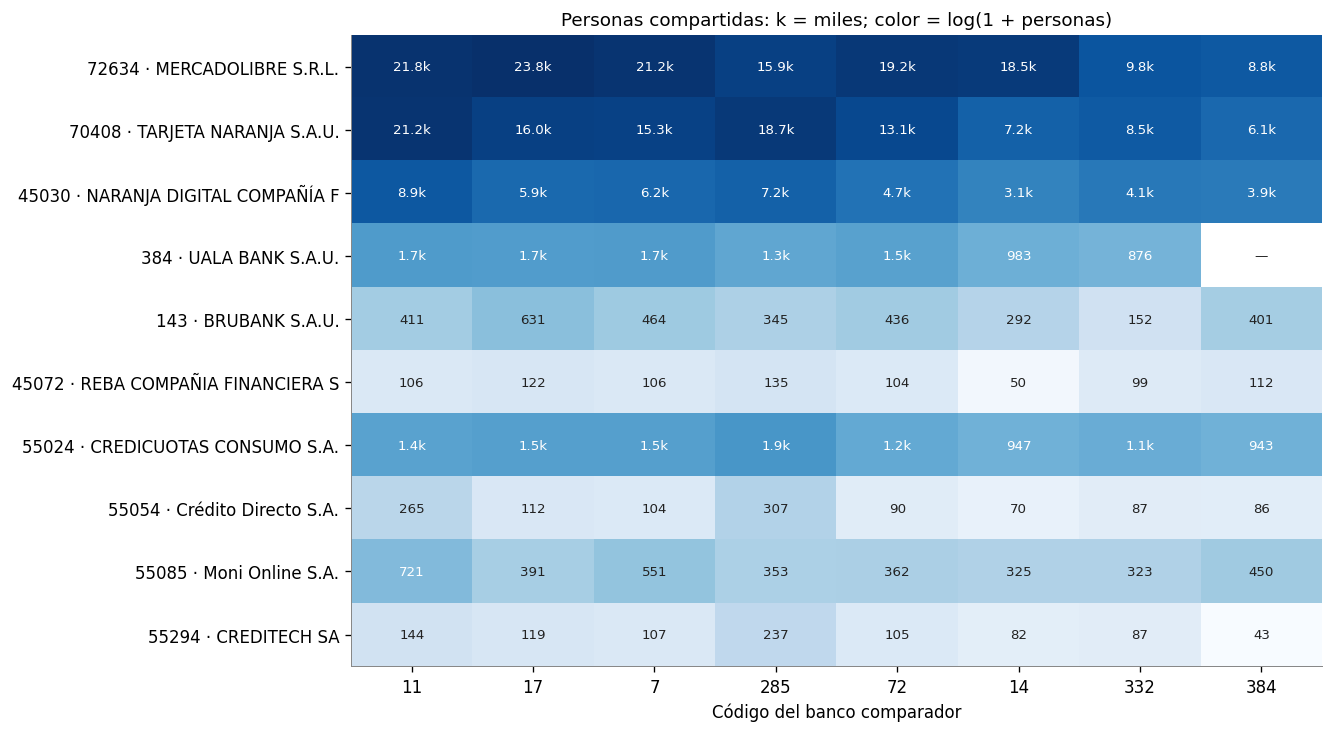

,ent,name
0,7,BANCO DE GALICIA Y BUENOS AIRES S.A.
1,11,BANCO DE LA NACION ARGENTINA
2,14,BANCO DE LA PROVINCIA DE BUENOS AIRES
5,17,BANCO BBVA ARGENTINA S.A.
13,72,BANCO SANTANDER ARGENTINA S.A.
34,285,BANCO MACRO S.A.
49,332,BANCO DE SERVICIOS FINANCIEROS CARREFOUR SAU
54,384,UALA BANK S.A.U.


In [5]:
d=pairs.loc[pairs.population.eq('person')]
banks=d.groupby('bank').shared.sum().nlargest(8).index.tolist()
matrix=d.pivot(index='focal',columns='bank',values='shared').reindex(index=focal_ids,columns=banks).fillna(0)
for ent in set(focal_ids)&set(banks):matrix.loc[ent,ent]=np.nan
fig,ax=plt.subplots(figsize=(11,6),layout='constrained')
im=ax.imshow(np.log1p(matrix),cmap='Blues',aspect='auto')
for i in range(len(focal_ids)):
    for j in range(len(banks)):
        v=matrix.iloc[i,j]
        label='—' if pd.isna(v) else (str(int(v)) if v<1000 else f'{v/1000:.1f}k')
        ax.text(j,i,label,ha='center',va='center',fontsize=8,color='white' if np.log1p(v)>np.log1p(np.nanmax(matrix))*.65 else '#222')
ax.set_xticks(range(len(banks)),[str(x) for x in banks]);ax.set_yticks(range(len(focal_ids)),[f'{x} · {labels.set_index("ent").loc[x,"name"][:26]}' for x in focal_ids])
ax.set_xlabel('Código del banco comparador');ax.set_title('Personas compartidas: k = miles; color = log(1 + personas)')
save_figure(fig,'06_soporte_pares');plt.show()
display(labels.loc[labels.ent.isin(banks)])


## Geografía y actividad: medir el cruce, no asumirlo

El panel de saldos no contiene ubicación. Se cruza el padrón por CUIT y se cuantifica cobertura entre deudores de mayo de 2025. El padrón es un corte: domicilio fiscal actual no equivale a residencia histórica ni a lugar de uso del préstamo. Código postal no se convierte automáticamente en localidad o departamento. La actividad tampoco es necesariamente una característica histórica estable.

Se exige unicidad del padrón antes de usarlo; se exportan únicamente agregados.

In [6]:
padron=CENDEU/'padron.parquet'
duplicates=con.execute('SELECT count(*)-count(DISTINCT cuit) FROM read_parquet(?)',[str(padron)]).fetchone()[0]
assert duplicates==0, 'El padrón no es único: resolver antes de cruzar.'
province_map=pd.read_csv(root/'Data/crosswalks/provincias_arca_indec.csv')
con.register('province_map',province_map)
geo=[];geo_detail=[]
for kind,mapping in [('person',calendar),('firm',firm_calendar)]:
    con.execute("""CREATE OR REPLACE TEMP TABLE geo_join AS WITH people AS (
    SELECT cuit,sum(amount_ars) AS amount FROM read_parquet(?) WHERE amount_ars>0 GROUP BY cuit)
    SELECT p.amount,a.cuit IS NOT NULL AS matched,a.province,a.zip,a.activity,m.provincia
    FROM people p LEFT JOIN read_parquet(?) a USING(cuit)
    LEFT JOIN province_map m ON a.province=m.cod_prov_arca""",[str(mapping[BASELINE]),str(padron)])
    d=con.execute("""SELECT count(*) AS borrowers,count(*) FILTER(WHERE matched) AS matched,
    count(*) FILTER(WHERE provincia IS NOT NULL) AS mapped_province,
    count(*) FILTER(WHERE zip IS NOT NULL AND trim(zip) NOT IN ('','0','0000')) AS nonempty_zip,
    count(*) FILTER(WHERE activity IS NOT NULL AND activity>0) AS positive_activity,
    sum(amount) AS amount,sum(CASE WHEN provincia IS NOT NULL THEN amount ELSE 0 END) AS mapped_amount
    FROM geo_join""").fetchdf();d['population']=kind;geo.append(d)
    d=con.execute('SELECT provincia,count(*) AS borrowers,sum(amount) AS amount FROM geo_join GROUP BY provincia').fetchdf();d['population']=kind;geo_detail.append(d)
geo=pd.concat(geo,ignore_index=True)
for col in ['matched','mapped_province','nonempty_zip','positive_activity']:geo[col+'_pct']=100*geo[col]/geo.borrowers
geo.to_csv(OUT/'06_cobertura_padron.csv',index=False)
pd.concat(geo_detail,ignore_index=True).to_csv(OUT/'06_deudores_provincia.csv',index=False)
display(geo[['population','borrowers','matched_pct','mapped_province_pct','nonempty_zip_pct','positive_activity_pct']])


,population,borrowers,matched_pct,mapped_province_pct,nonempty_zip_pct,positive_activity_pct
0,person,970955,99.88,99.88,99.05,44.40
1,firm,254195,100.00,100.00,100.00,99.86


## El panel territorial que ya existe

Se auditan claves, períodos con información efectiva y variación. No se imputa monto en meses sin publicación trimestral. La coincidencia de provincia permite un cruce agregado; no demuestra que el domicilio fiscal y la asignación territorial del balance midan el mismo lugar. La cuota de cuentas de pago describe tenencia, no intensidad de uso ni crédito fintech.

,concepto,valor
0,Meses con crédito observado en ventana CENDEU,7
1,Pares entidad–provincia,425
2,Pares con todos esos trimestres,385
3,Último mes cuentas de pago,2025-12-01


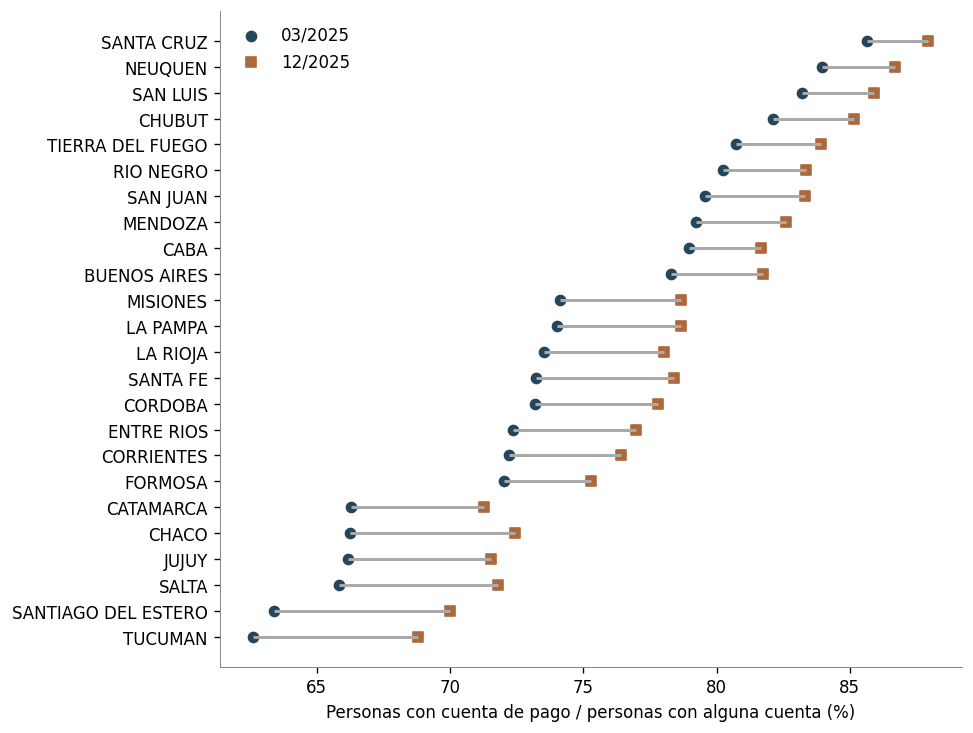

In [7]:
prov=pd.read_stata(DATA/'prestamos_depositos_prov.dta',convert_categoricals=False)
inc=pd.read_stata(DATA/'inclusion_prov.dta',convert_categoricals=False)
assert not prov.duplicated(['ent','provincia','ym']).any()
assert not inc.duplicated(['provincia','ym']).any()
coverage=prov.groupby('ym').agg(rows=('ent','size'),credit_nonmissing=('prestamos_prov','count'),deposit_nonmissing=('depositos_prov','count')).reset_index()
coverage.to_csv(OUT/'06_cobertura_provincial.csv',index=False)
inc['payment_account_share']=100*inc.n_pers_min1_cta_pago/inc.n_pers_min1_cta.replace(0,np.nan)
valid=inc.loc[inc.payment_account_share.notna()]
pre=valid.loc[valid.ym.eq(valid.loc[valid.ym.le(BASELINE),'ym'].max())].copy()
post=valid.loc[valid.ym.eq(valid.ym.max())].copy()
territory=pre[['provincia','ym','payment_account_share']].merge(post[['provincia','ym','payment_account_share']],on='provincia',suffixes=('_pre','_last'),validate='one_to_one')
territory['change_pp']=territory.payment_account_share_last-territory.payment_account_share_pre
territory.to_csv(OUT/'06_cuentas_pago_provincias.csv',index=False)
window=prov.loc[prov.ym.between('2024-08-01','2026-06-01')&prov.prestamos_prov.notna()]
pairs_coverage=window.groupby(['ent','provincia']).agg(quarters=('ym','nunique'),credit_min=('prestamos_prov','min'),credit_max=('prestamos_prov','max')).reset_index()
pairs_coverage.to_csv(OUT/'06_soporte_banco_provincia.csv',index=False)
display(pd.DataFrame({'concepto':['Meses con crédito observado en ventana CENDEU','Pares entidad–provincia','Pares con todos esos trimestres','Último mes cuentas de pago'], 'valor':[window.ym.nunique(),len(pairs_coverage),pairs_coverage.quarters.eq(window.ym.nunique()).sum(),str(valid.ym.max().date())]}))
fig,ax=plt.subplots(figsize=(8,6),layout='constrained')
d=territory.sort_values('payment_account_share_pre');y=np.arange(len(d))
ax.hlines(y,d.payment_account_share_pre,d.payment_account_share_last,color='#aaa')
ax.scatter(d.payment_account_share_pre,y,label=f'{d.ym_pre.iloc[0]:%m/%Y}',color='#24465B',marker='o')
ax.scatter(d.payment_account_share_last,y,label=f'{d.ym_last.iloc[0]:%m/%Y}',color='#AD683B',marker='s')
ax.set_yticks(y,d.provincia);ax.set_xlabel('Personas con cuenta de pago / personas con alguna cuenta (%)');ax.legend()
save_figure(fig,'06_cuentas_pago_geografia');plt.show()


## Dispersión de exposiciones y soporte temporal

Los balances permiten explorar fondeo y cartera sin imponer un episodio. Se muestran distribuciones previas, no tratamientos validados. Un ratio contable heterogéneo no es una fuente exógena de variación. La cuenta de pago provincial puede construir exposición territorial predeterminada, pero sus pesos y la exclusión requieren una justificación económica y una ventana compatible con CENDEU.

In [8]:
pre_bank=balance.loc[balance.ym.eq(BASELINE)&balance.es_banco.eq(1)].copy()
for col in ['depositos','efectivo','titulos']:pre_bank[col+'_asset_pct']=100*pre_bank[col]/pre_bank.activo.replace(0,np.nan)
exposure=pre_bank[['ent','nombre','depositos_asset_pct','efectivo_asset_pct','titulos_asset_pct']]
exposure.to_csv(OUT/'06_exposiciones_bancarias.csv',index=False)
display(exposure.drop(columns=['ent','nombre']).describe().loc[['count','min','25%','50%','75%','max']])
# Concentración de pesos territoriales por banco con depósitos publicados en 2025Q1.
weights=prov.loc[prov.ym.eq(pd.Timestamp('2025-03-01'))&prov.es_banco.eq(1)&prov.depositos_prov.gt(0),['ent','provincia','depositos_prov']].copy()
weights['weight']=weights.depositos_prov/weights.groupby('ent').depositos_prov.transform('sum')
assert np.allclose(weights.groupby('ent').weight.sum(),1)
weights=weights.merge(pre[['provincia','payment_account_share']],on='provincia',how='left',validate='many_to_one')
weights['weighted_access']=weights.weight*weights.payment_account_share
bank_geography=weights.groupby('ent').agg(provinces=('provincia','nunique'),max_weight=('weight','max'),mapped_weight=('weight',lambda x: x.sum())).reset_index()
# No calcular exposición si falta una provincia con peso positivo.
covered=weights.assign(covered_weight=weights.weight.where(weights.payment_account_share.notna(),0)).groupby('ent').covered_weight.sum()
exposure_geo=weights.groupby('ent').weighted_access.sum(min_count=1).where(covered.ge(.999999))
bank_geography=bank_geography.merge(exposure_geo.rename('payment_exposure'),on='ent')
bank_geography.to_csv(OUT/'06_exposicion_territorial.csv',index=False)
display(bank_geography[['provinces','max_weight','payment_exposure']].describe().loc[['count','min','50%','max']])



,depositos_asset_pct,efectivo_asset_pct,titulos_asset_pct
count,61.00,61.00,61.00
min,0.00,1.05,0.00
25%,47.73,6.87,18.76
50%,63.65,9.60,28.80
75%,70.39,16.08,39.39
max,94.45,30.07,76.25


,provinces,max_weight,payment_exposure
count,59.00,59.00,59.00
min,1.00,0.36,62.61
50%,3.00,0.97,78.48
max,24.00,1.00,85.16


## Sensibilidades que cambian la interpretación

La entrada sin saldo en seis meses se contrasta con toda la historia disponible. Ni siquiera esta segunda medida identifica el primer crédito de la vida. El seguimiento cuenta saldo con **otro** banco, excluyendo la entidad focal cuando también es banco; no equivale a una apertura bancaria nueva. La figura de persistencia omite grupos con menos de 100 entradas.

Se comparan dos ponderadores territoriales anteriores: depósitos y sucursales plenas. Diferencias grandes indicarían que elegir pesos es sustantivo. La concentración puede reflejar centralización de la información; no se la interpreta automáticamente como concentración de clientes. El soporte multibanco ponderado por monto usa el saldo de todos los reportantes, incluidas garantías, y no debe citarse como cuota del crédito bancario.

In [9]:
# La historia completa observable acota las reapariciones tras seis meses sin saldo.
no_history=pooled.loc[pooled.prior_profile.eq('Sin saldo en seis meses previos'),['ent','name','persons','new_to_window','positive6_pct','with_other_bank6_pct']].copy()
no_history['first_in_window_pct']=100*no_history.new_to_window/no_history.persons
no_history.to_csv(OUT/'06_entrada_historia_completa.csv',index=False)
display(no_history)
# Comprobar si depósitos y sucursales representan exposiciones territoriales parecidas.
branches=prov.loc[prov.ym.eq(pd.Timestamp('2025-03-01'))&prov.es_banco.eq(1)&prov.suc_plenas.gt(0),['ent','provincia','suc_plenas']].copy()
branches['weight']=branches.suc_plenas/branches.groupby('ent').suc_plenas.transform('sum')
assert np.allclose(branches.groupby('ent').weight.sum(),1)
branches=branches.merge(pre[['provincia','payment_account_share']],on='provincia',how='left',validate='many_to_one')
assert branches.payment_account_share.notna().all()
branches['weighted_access']=branches.weight*branches.payment_account_share
branch_geo=branches.groupby('ent').agg(branch_provinces=('provincia','nunique'),branch_max_weight=('weight','max'),branch_exposure=('weighted_access','sum')).reset_index()
comparison=bank_geography.merge(branch_geo,on='ent',how='outer',validate='one_to_one')
comparison['exposure_difference_pp']=comparison.payment_exposure-comparison.branch_exposure
comparison.to_csv(OUT/'06_geografia_pesos_alternativos.csv',index=False)
both=comparison.dropna(subset=['payment_exposure','branch_exposure'])
display(comparison[['max_weight','branch_max_weight','exposure_difference_pp']].describe())
print('Bancos con ambos pesos:',len(both))
print('Correlación de rangos:',both.payment_exposure.rank().corr(both.branch_exposure.rank()))
con.close()


,ent,name,persons,new_to_window,positive6_pct,with_other_bank6_pct,first_in_window_pct
1,143,BRUBANK S.A.U.,594,567,57.91,9.26,95.45
4,384,UALA BANK S.A.U.,1422,1352,44.87,6.61,95.08
7,45030,NARANJA DIGITAL COMPAÑÍA FINANCIERA S.A.U.,3486,3003,71.86,5.36,86.14
10,45072,REBA COMPAÑIA FINANCIERA S.A.,247,231,82.59,10.53,93.52
13,55024,CREDICUOTAS CONSUMO S.A.,371,349,82.48,16.44,94.07
16,55054,Crédito Directo S.A.,561,516,70.77,7.49,91.98
19,55085,Moni Online S.A.,10,10,80.00,30.00,100.00
22,55294,CREDITECH SA,487,458,75.77,14.17,94.05
25,70408,TARJETA NARANJA S.A.U.,9911,9280,84.36,8.75,93.63
28,72634,MERCADOLIBRE S.R.L.,64133,62501,54.48,6.30,97.46


,max_weight,branch_max_weight,exposure_difference_pp
count,59.00,60.00,58.00
mean,0.85,0.76,0.45
std,0.19,0.27,1.03
min,0.36,0.20,-2.81
25%,0.71,0.50,0.00
50%,0.97,0.86,0.07
75%,1.00,1.00,0.89
max,1.00,1.00,3.71


Bancos con ambos pesos: 58
Correlación de rangos: 0.9698659332341375


## Cómo decidir la siguiente etapa

**Acceso:** avanzar si hay suficientes primeras relaciones sin saldo previo, repetidas en varias cohortes y entidades, y observar qué proporción mantiene saldo o suma otros acreedores. La censura inicial y transferencias impiden llamar a esto bancarización causal.

**Competencia:** elegir pares por soporte previo y estabilidad de identidad, no por el signo de sus resultados. Estudiar cambios de saldo conjunto, relación focal y alternativas en panel mensual; no seleccionar a quienes perdieron crédito después del hecho. Los efectos fijos deudor×mes separan shocks comunes del deudor, pero no diferencias de producto, contrato o reporte. Para estimar efectos sobre el saldo total se necesita además variación entre deudores.

**Geografía:** si el padrón enlaza y el panel provincial tiene cobertura, comparar expansión y alternativas por provincias y exposición territorial de bancos. El detalle de sucursales no resuelve automáticamente el puente de código postal a localidad ni convierte aperturas/cierres en instrumentos.

**Mecanismos:** fondeo, liquidez, red de sucursales y composición de clientes quedan como hipótesis competidoras. Tasas y LEFI solo se priorizan si una exposición medible y una variación defendible explican el contraste elegido. No estimar primero una regresión y buscar después su historia.

La próxima especificación debe declarar población, resultado, comparación, fuente de variación y amenaza principal. Este notebook mide soporte y cobertura; no declara identificado un efecto causal.

## Lectura de los resultados y diseño que merece avanzar

**Hay dos márgenes observables con soporte.** En las cohortes marzo–diciembre de 2025, 40,2% de las primeras relaciones con MercadoLibre corresponden a personas sin saldo en los seis meses anteriores; 49,8% ya tenían un banco. La primera proporción es 26,6% en Brubank, 15,3% en Ualá y 7,8% en Naranja Digital. Estas diferencias describen composición de clientes, no impactos comparables de las entidades. Entre las 64.133 entradas de MercadoLibre sin saldo previo, 97,5% tampoco tenía saldo anterior en toda la ventana observable y 54,5% mantiene saldo con la entidad seis meses después. Mantener deuda no es una medida de bienestar ni de renovación del préstamo.

**Competencia tiene soporte micro, con selección explícita.** Hay 168.005 personas de la muestra y 74.958 firmas con al menos dos bancos en mayo de 2025: 23,6% y 30,3% de quienes tienen algún banco, respectivamente. Las firmas multibanco concentran 93,9% del saldo de todos los reportantes del universo de firmas; no representan 93,9% de las firmas. Ese margen puede ayudar a estimar componentes banco–mes controlando demanda común del deudor, pero no garantiza que sean shocks exógenos ni que se trasladen igual al crédito de personas. Antes hay que resolver continuidad de códigos, concentración, moneda y composición contractual.

**La vía territorial existe.** El padrón permite asignar provincia a 99,88% de las personas y casi todas las firmas del corte. Hay 385 pares banco–provincia con préstamos observados en los siete trimestres disponibles dentro de la ventana. No hace falta descartar esta vía por falta de banca provincial. Sí falta validar ubicación histórica y el puente postal–departamento. La exposición a cuentas de pago calculada con depósitos o sucursales tiene correlación de rangos cercana a 0,97 entre 58 bancos: el orden es bastante estable. Sin embargo, pesos muy concentrados y solo 24 provincias limitan una interpretación de muchos shocks independientes. La variable mide tenencia de cuenta de pago entre personas con alguna cuenta, no penetración entre todos los adultos ni uso efectivo.

**La pregunta candidata:** ¿en qué condiciones los prestamistas digitales amplían las alternativas de crédito y en cuáles redistribuyen relaciones que ya existían con bancos? La evidencia permite desarrollar esta pregunta; todavía no permite responderla causalmente ni establecer un mecanismo ganador.

La siguiente etapa tiene tres decisiones concretas:

1. **Medición y población:** fechar identidades de acreedores y transferencias; mantener separados primer saldo observado, retorno y relación existente. Formar pares por soporte previo. Las diez entidades son un conjunto exploratorio explícito, no una definición exhaustiva de fintech ni una muestra elegida por significancia.
2. **Dos resultados complementarios:** en personas ya endeudadas, estudiar mensualmente saldo focal, alternativas y saldo conjunto en cohortes fijadas antes del cambio; en personas sin saldo previo, medir entradas y persistencia con denominadores de población en riesgo. Este último análisis requiere construir un conjunto de comparación de personas elegibles: la distribución de quienes entran no estima la probabilidad de acceder. Cruzar ambos con provincia, red bancaria y características disponibles, manteniendo comparaciones dentro de entidad.
3. **Variación y mecanismo:** evaluar componentes bancarios con firmas multibanco y exposiciones previas de fondeo/red. Si se trasladan a personas, usar pesos previos y construcción fuera de la muestra de resultados; documentar qué demanda residual podría contaminar el shock. Los balances disponibles son bancarios, no de todos los prestamistas digitales. Un componente banco–mes, una interacción de tasas o un Bartik no son instrumentos por construcción. Tasas/LEFI, competencia territorial y composición de clientes permanecen como explicaciones alternativas; la variación institucional se elige con evidencia externa, no por el signo que produjo este notebook.

Ejecutado completo el 22 de septiembre de 2026. Se revisaron las cuatro figuras y la exportación HTML, claves de los cruces y reconciliaciones de cohortes. Salidas agregadas con prefijo `06_`; no se exportan identificadores personales. La definición de acceso es observacional y la identificación causal sigue pendiente.
